=== BIO_CANCER_LOG v1.0 | MODE = FAST | TCGA-BRCA ===
  Estimations : 1 | Fenêtre : 80 patientes | Test : cohen_d
  Seuil critique (hypothèse) : 65.0e percentile

Gradient de progression : 29 points

[1/6] Téléchargement TCGA-BRCA depuis GDC API...
[GDC API] Téléchargement TCGA-BRCA (1000 cas)...
  [DEBUG] Champs disponibles dans diagnoses : ['age_at_diagnosis', 'ajcc_pathologic_m', 'ajcc_pathologic_n', 'ajcc_pathologic_stage', 'ajcc_pathologic_t', 'days_to_last_follow_up', 'tumor_grade']
  1000 cas totaux → 913 avec stade connu
[OK] 913 patientes | Stade I:162 II:530 III:201 IV:20
     Âge : 58.9 ± 13.2 ans | Décédées : 0 (0.0%)

[2/6] Extraction des flux biologiques et du score de progression...
  Score de progression : min=8.9 | max=99.0 | mean=50.1

[3/6] Scan du seuil critique (40–85e percentile)...


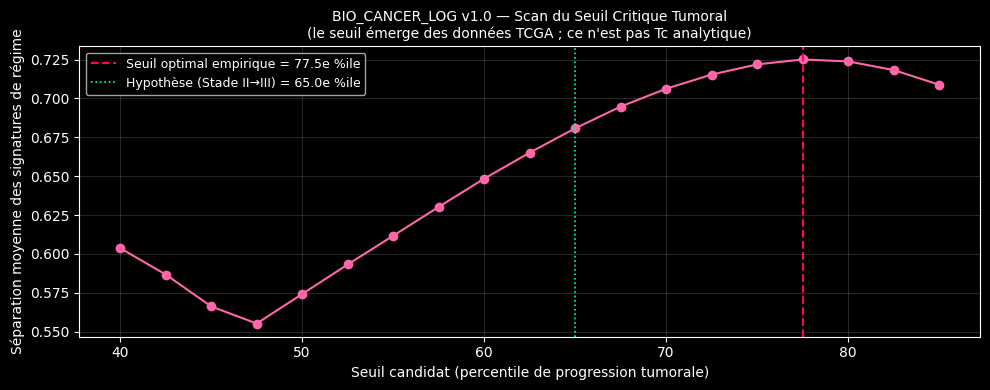


[Scan du seuil critique]
  Hypothèse initiale (Stade II→III) : 65.0e percentile
  Seuil optimal TCGA-BRCA           : 77.5e percentile (séparation = 0.725)

[4/6] Vue d'ensemble clinique TCGA-BRCA...


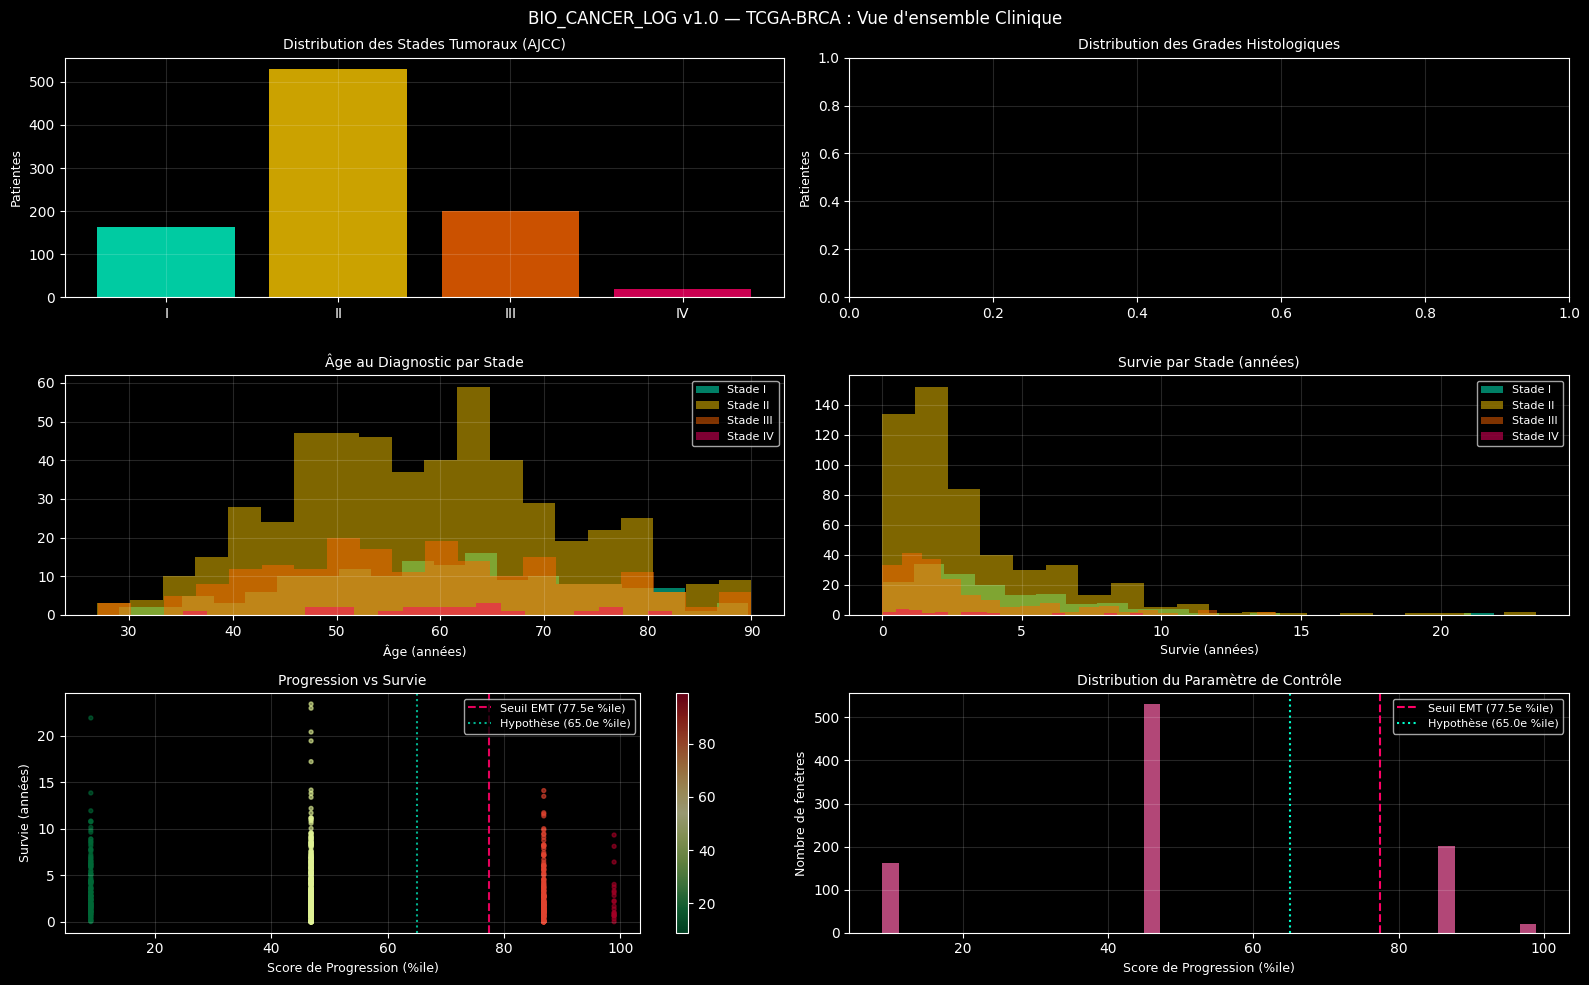

      Profils des 5 flux biologiques...


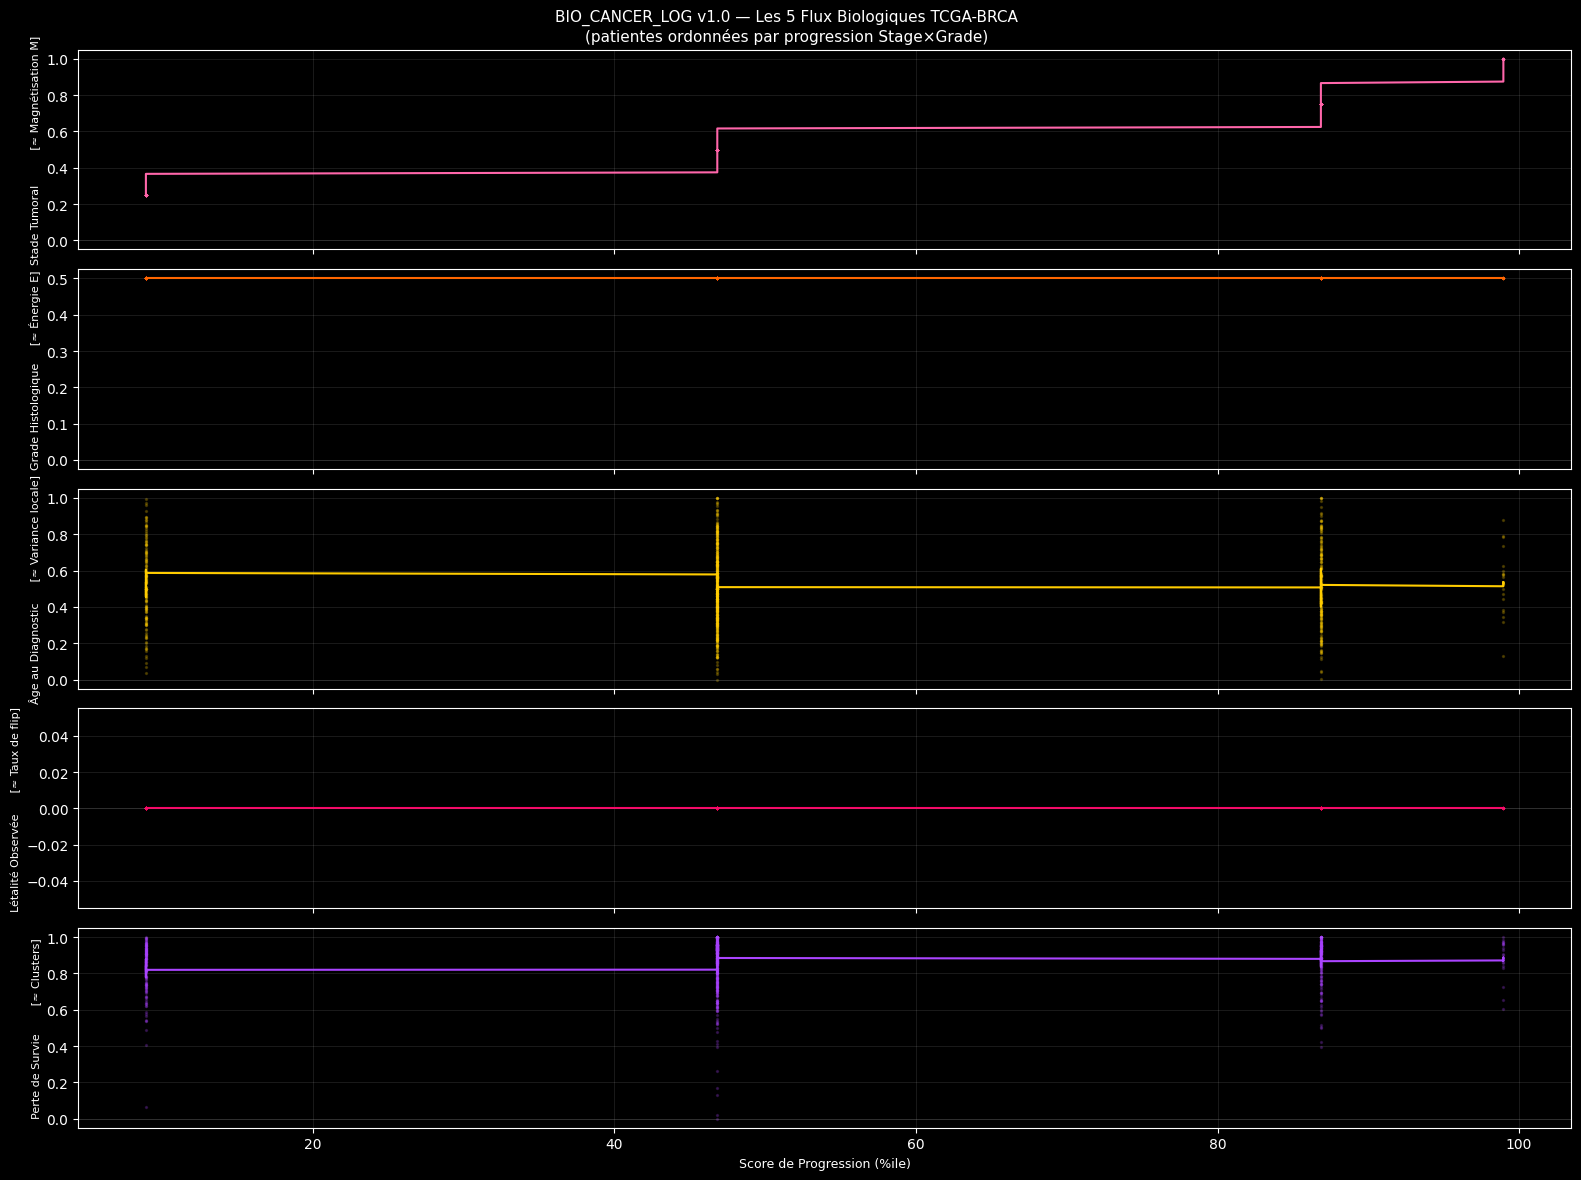


[5/6] Extraction des signatures de régime...

[Extraction des signatures de régime] 1 cohorte unique | Fenêtre=80 patientes


Scan de progression tumorale: 100%|██████████| 29/29 [02:35<00:00,  5.36s/it]


  Signatures extraites : 25
   Progress  N_cohorts  Stage_Signal_Higuchi_mean  Stage_Signal_DFA_mean  Stage_Signal_Katz_mean  Stage_Signal_Hurst_mean
0       5.0          1                        NaN                    NaN                     NaN                      NaN
1      10.0         91                   1.365302               1.624911                1.437863                 0.318400
2      15.0         13                   1.009284               0.732857                1.863632                 0.644915


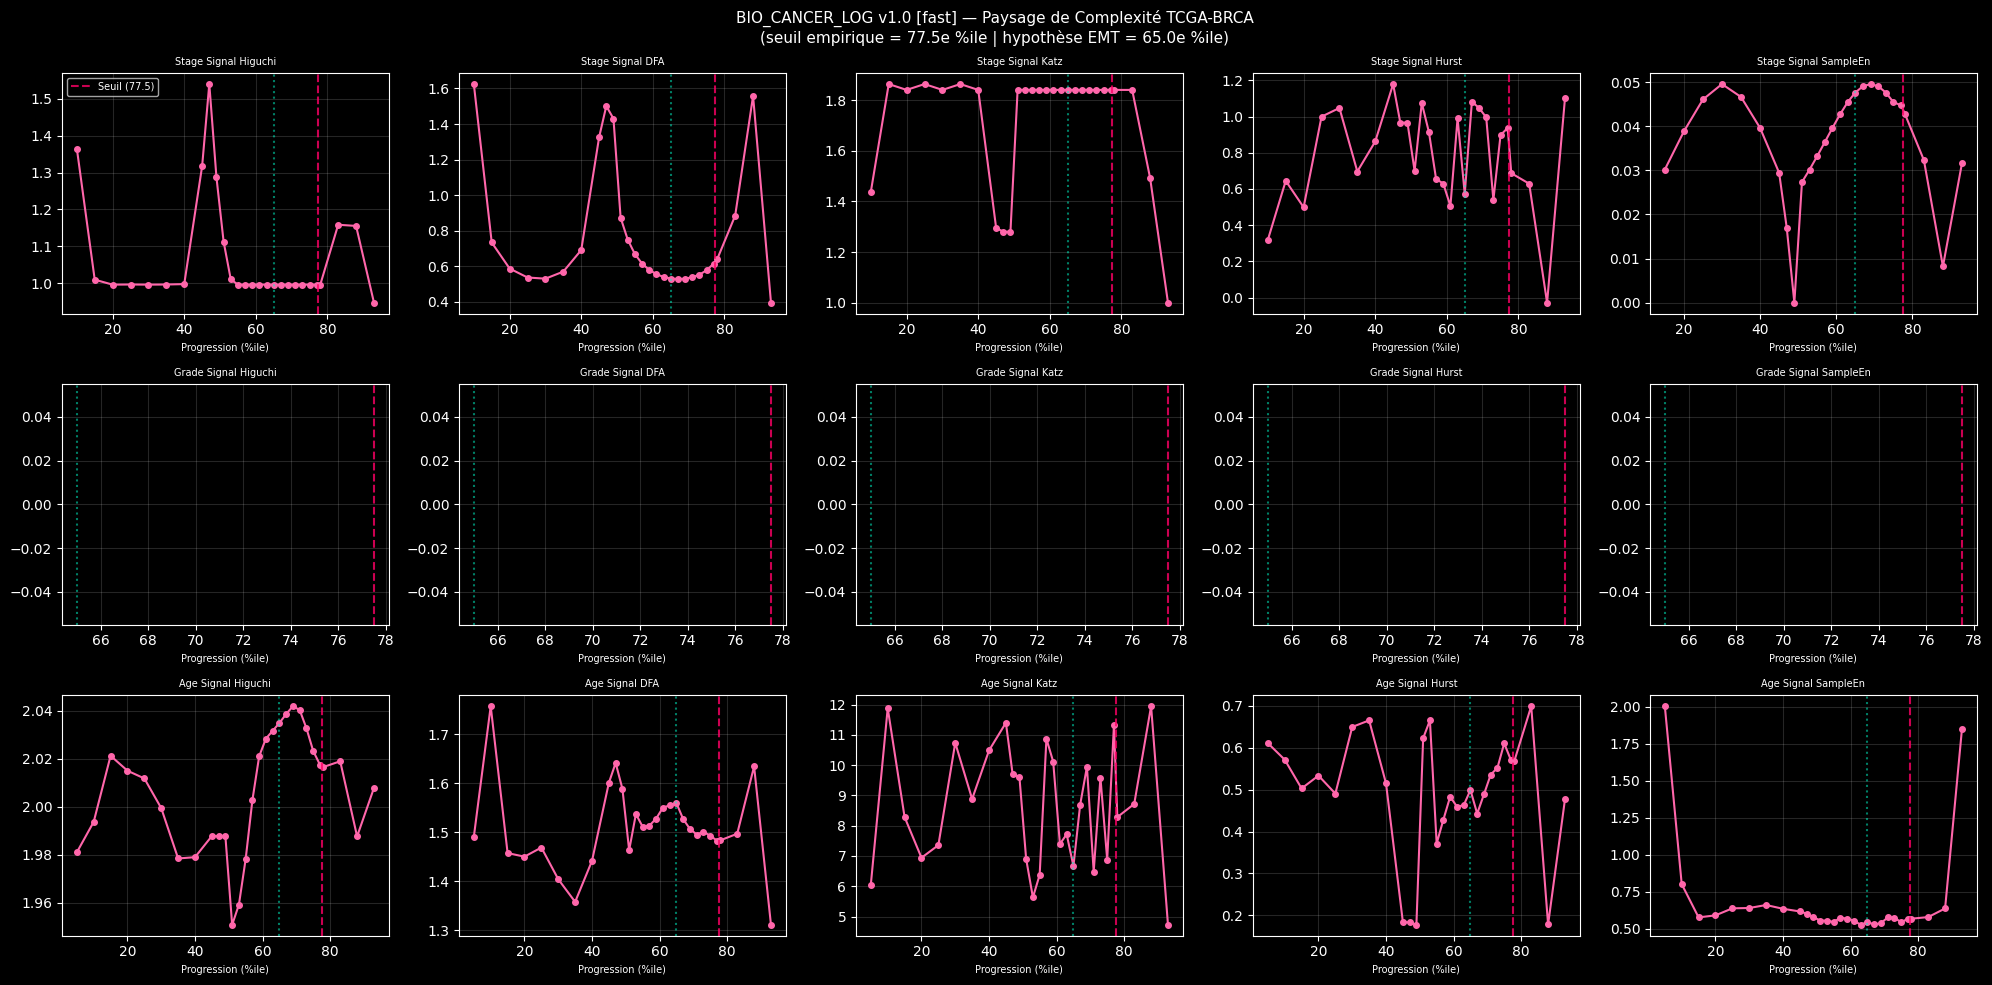


[6/6] 4 Questions cancérologiques...

=== 4 Questions Cancérologiques (seuil empirique = 77.5e %ile) ===
Q1 : Phase Localisée vs Métastatique (Stade I–II vs III–IV)...
Q2 : Tension à la Transition EMT (zone de basculement critique)...
Q3 : Agressivité Tumorale (Grade + Létalité)...
Q4 : Persistance de Régime (hystérésis intra-cohorte)...

>>> RÉSULTATS — Scores de séparation des signatures de régime :
                                Q1_Localise_vs_Metastatique  Q2_Tension_Transition_EMT  Q3_Agressivite_Tumorale  Q4_Persistance_Regime
Age_Signal_DFA_mean                                   0.084                      0.334                      NaN                  0.191
Age_Signal_Higuchi_mean                               1.246                      2.477                      NaN                  0.191
Age_Signal_Hurst_mean                                 0.367                      0.326                      NaN                  0.191
Age_Signal_Katz_mean                                  

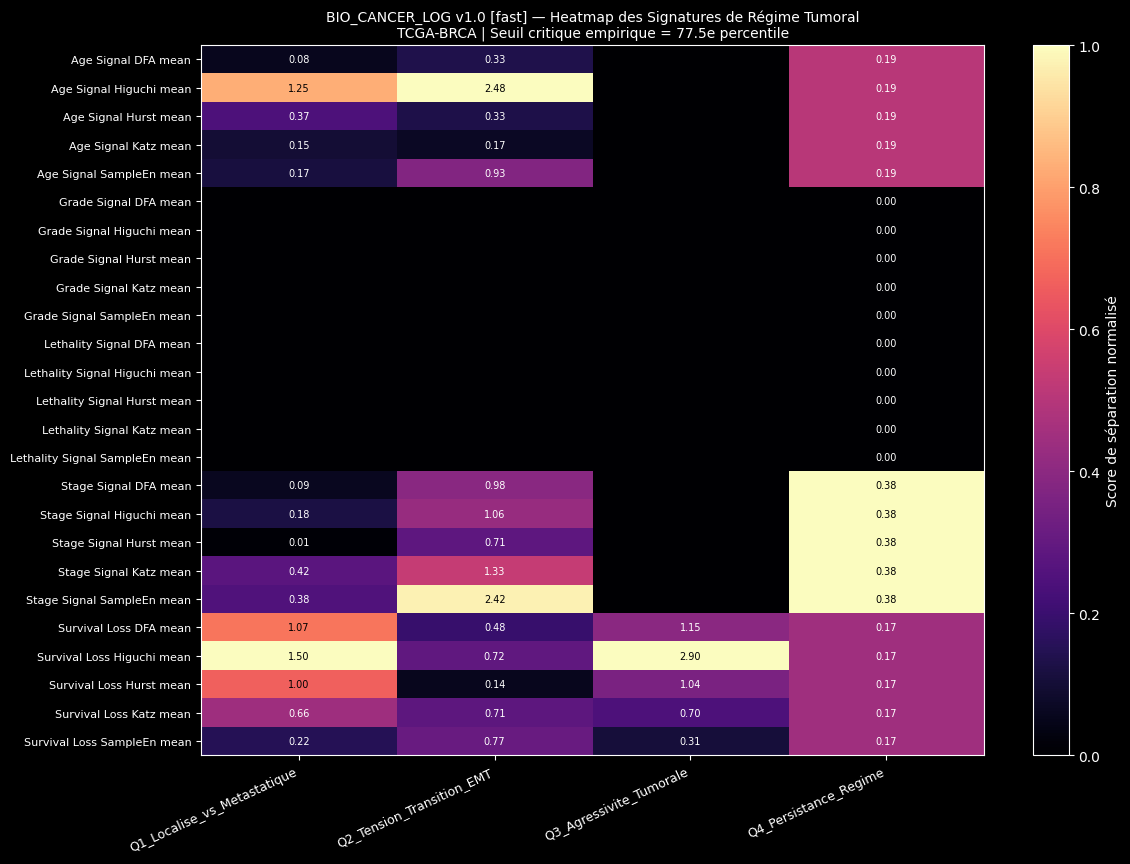


[OK] BIO_CANCER_LOG v1.0 terminé.
     913 patientes TCGA-BRCA | Seuil EMT empirique : 77.5e percentile


In [2]:
!pip install -q nolds antropy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy import stats
import requests, json
import warnings
warnings.filterwarnings('ignore')
import antropy, nolds

plt.style.use('dark_background')

PROGRESS_CRITIQUE_HYPOTHESE = 65.0
MODE = 'fast'

CONFIG = {
    'fast': {
        'n_estimations': 1,
        'window_size': 80,
        'stat_test': 'cohen_d',
        'min_per_group': 2,
        'estimator_min_len': 50,
        'mann_whitney': False,
        'bootstrap': False,
    },
    'robust': {
        'n_estimations': 5,
        'window_size': 150,
        'stat_test': 'cliff_delta',
        'min_per_group': 3,
        'estimator_min_len': 80,
        'mann_whitney': True,
        'bootstrap': True,
    }
}
C = CONFIG[MODE]
print(f"=== BIO_CANCER_LOG v1.0 | MODE = {MODE.upper()} | TCGA-BRCA ===")
print(f"  Estimations : {C['n_estimations']} | Fenêtre : {C['window_size']} patientes | "
      f"Test : {C['stat_test']}")
print(f"  Seuil critique (hypothèse) : {PROGRESS_CRITIQUE_HYPOTHESE}e percentile")

# =============================================================================
# 0. STATISTIQUES
# =============================================================================

def cohen_d(g1, g2):
    g1, g2 = np.asarray(g1), np.asarray(g2)
    if len(g1) < 2 or len(g2) < 2: return np.nan
    pooled_std = np.sqrt((np.var(g1, ddof=1) + np.var(g2, ddof=1)) / 2.0)
    return 0.0 if pooled_std < 1e-12 else (np.mean(g1) - np.mean(g2)) / pooled_std

def cliff_delta(g1, g2):
    g1, g2 = np.asarray(g1), np.asarray(g2)
    n1, n2 = len(g1), len(g2)
    if n1 < C['min_per_group'] or n2 < C['min_per_group']: return np.nan, np.nan
    try:
        U, _ = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        return np.clip((2 * U - n1 * n2) / (n1 * n2), -1, 1), np.nan
    except: return np.nan, np.nan

def separation_score(g1, g2):
    if C['stat_test'] == 'cohen_d':
        d = cohen_d(g1, g2)
        return abs(d) if not np.isnan(d) else np.nan
    else:
        d, _ = cliff_delta(g1, g2)
        return abs(d) if not np.isnan(d) else np.nan

def mw_score(g1, g2):
    if not C['mann_whitney']: return np.nan
    try:
        _, p = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        return -np.log10(max(p, 1e-300))
    except: return np.nan

# =============================================================================
# 1. ACQUISITION — GDC API TCGA-BRCA (détection automatique des champs)
# =============================================================================

def encode_stage(s):
    """
    Encode le stade AJCC en score [0.25–1.0].
    Gère : 'Stage I/IA/IB', 'Stage II/IIA/IIB', 'Stage III/IIIA/IIIB/IIIC', 'Stage IV'.
    """
    if not isinstance(s, str): return np.nan
    s = s.lower().strip()
    if any(x in s for x in ['not reported','unknown','stage x','indeterminate',
                             'not applicable','stage 0']): return np.nan
    if 'iv' in s:  return 1.00
    if 'iii' in s: return 0.75
    if 'ii' in s:  return 0.50
    if 'i' in s:   return 0.25
    return np.nan

def encode_grade(g):
    if not isinstance(g, str): return np.nan
    g = g.lower().strip()
    if any(x in g for x in ['not reported','unknown','gx','not applicable']): return np.nan
    if 'g4' in g or 'grade 4' in g or 'anaplastic' in g: return 1.00
    if 'g3' in g or 'grade 3' in g: return 0.75
    if 'g2' in g or 'grade 2' in g: return 0.50
    if 'g1' in g or 'grade 1' in g: return 0.25
    # Breast-specific grades
    if 'poorly' in g:      return 0.75
    if 'moderately' in g:  return 0.50
    if 'well' in g:        return 0.25
    return np.nan

def encode_t_stage(t):
    """
    Encode le stade T (taille tumorale) depuis ajcc_pathologic_t.
    T1 < 2cm → T4 = invasion directe.
    """
    if not isinstance(t, str): return np.nan
    t = t.lower().strip()
    if any(x in t for x in ['tx','t0','tis','not reported']): return np.nan
    if 't4' in t: return 1.00
    if 't3' in t: return 0.75
    if 't2' in t: return 0.50
    if 't1' in t: return 0.25
    return np.nan

def encode_n_stage(n):
    """
    Encode le stade N (envahissement ganglionnaire) depuis ajcc_pathologic_n.
    N0 = aucun ganglion → N3 = envahissement massif.
    """
    if not isinstance(n, str): return np.nan
    n = n.lower().strip()
    if any(x in n for x in ['nx','not reported']): return np.nan
    if 'n3' in n: return 1.00
    if 'n2' in n: return 0.67
    if 'n1' in n: return 0.33
    if 'n0' in n: return 0.00
    return np.nan


def fetch_tcga_brca(n_cases=1000):
    """
    Télécharge les données cliniques TCGA-BRCA depuis GDC.
    Détecte automatiquement le champ de stade disponible dans la réponse API.
    Champs prioritaires : ajcc_pathologic_stage > tumor_stage > ajcc_pathologic_t
    """
    url = "https://api.gdc.cancer.gov/cases"

    filters = json.dumps({
        "op": "in",
        "content": {
            "field": "project.project_id",
            "value": ["TCGA-BRCA"]
        }
    })

    # On demande tous les champs potentiels — GDC ignorera ceux qui n'existent pas
    fields = ",".join([
        "case_id",
        "diagnoses.ajcc_pathologic_stage",
        "diagnoses.tumor_stage",
        "diagnoses.age_at_diagnosis",
        "diagnoses.days_to_death",
        "diagnoses.days_to_last_follow_up",
        "diagnoses.vital_status",
        "diagnoses.tumor_grade",
        "diagnoses.ajcc_pathologic_t",
        "diagnoses.ajcc_pathologic_n",
        "diagnoses.ajcc_pathologic_m",
    ])

    params = {
        "filters": filters,
        "fields":  fields,
        "format":  "json",
        "size":    n_cases
    }

    print(f"[GDC API] Téléchargement TCGA-BRCA ({n_cases} cas)...")
    resp = requests.get(url, params=params, timeout=60)
    resp.raise_for_status()
    hits = resp.json()['data']['hits']

    # Debug : montrer les clés disponibles dans le premier cas avec diagnoses
    for h in hits[:20]:
        if h.get('diagnoses'):
            d0 = h['diagnoses'][0]
            print(f"  [DEBUG] Champs disponibles dans diagnoses : {sorted(d0.keys())}")
            break

    records = []
    for hit in hits:
        diags = hit.get('diagnoses', [{}])
        d = diags[0] if diags else {}

        # Stade : priorité ajcc_pathologic_stage > tumor_stage
        stage_raw = (d.get('ajcc_pathologic_stage') or
                     d.get('tumor_stage') or None)

        records.append({
            'case_id':      hit.get('case_id', ''),
            'stage_raw':    stage_raw,
            'age_days':     d.get('age_at_diagnosis', None),
            'days_death':   d.get('days_to_death', None),
            'days_follow':  d.get('days_to_last_follow_up', None),
            'vital_status': d.get('vital_status', None),
            'grade_raw':    d.get('tumor_grade', None),
            't_raw':        d.get('ajcc_pathologic_t', None),
            'n_raw':        d.get('ajcc_pathologic_n', None),
        })

    df = pd.DataFrame(records)

    # Encodage
    df['stage_score'] = df['stage_raw'].apply(encode_stage)
    df['grade_score'] = df['grade_raw'].apply(encode_grade)
    df['t_score']     = df['t_raw'].apply(encode_t_stage)
    df['n_score']     = df['n_raw'].apply(encode_n_stage)
    df['age_years']   = pd.to_numeric(df['age_days'], errors='coerce') / 365.25
    df['days_death']  = pd.to_numeric(df['days_death'], errors='coerce')
    df['days_follow'] = pd.to_numeric(df['days_follow'], errors='coerce')
    df['is_dead']     = df['vital_status'].str.lower().str.strip().eq('dead')
    df['survival_days'] = df['days_death'].where(df['is_dead'], df['days_follow'])
    df['survival_days'] = pd.to_numeric(df['survival_days'], errors='coerce').clip(lower=0)

    # Si stade AJCC absent, utiliser stade T comme proxy de progression
    mask_no_stage = df['stage_score'].isna()
    df.loc[mask_no_stage, 'stage_score'] = df.loc[mask_no_stage, 't_score']

    n_before = len(df)
    df = df.dropna(subset=['stage_score']).reset_index(drop=True)
    print(f"  {n_before} cas totaux → {len(df)} avec stade connu")

    if len(df) == 0:
        raise ValueError(
            "Aucun stade trouvé. Valeurs brutes uniques de stage_raw : "
            f"{df['stage_raw'].unique()[:10]}\n"
            "Vérifiez les champs disponibles dans [DEBUG] ci-dessus."
        )

    print(f"[OK] {len(df)} patientes | "
          f"Stade I:{(df['stage_score']==0.25).sum()} "
          f"II:{(df['stage_score']==0.50).sum()} "
          f"III:{(df['stage_score']==0.75).sum()} "
          f"IV:{(df['stage_score']==1.00).sum()}")
    print(f"     Âge : {df['age_years'].dropna().mean():.1f} ± "
          f"{df['age_years'].dropna().std():.1f} ans | "
          f"Décédées : {df['is_dead'].sum()} ({100*df['is_dead'].mean():.1f}%)")
    return df


def extract_cancer_fluxes(df):
    out = {}

    out['Stage_Signal'] = df['stage_score'].fillna(df['stage_score'].median()).values

    grade = df['grade_score'].fillna(df['grade_score'].median())
    if grade.isna().all(): grade = pd.Series(np.full(len(df), 0.5))
    out['Grade_Signal'] = grade.values

    age_min, age_max = df['age_years'].min(), df['age_years'].max()
    age_norm = (df['age_years'] - age_min) / (age_max - age_min + 1e-10)
    out['Age_Signal'] = age_norm.fillna(0.5).values

    out['Lethality_Signal'] = df['is_dead'].astype(float).values

    max_surv = df['survival_days'].dropna().max()
    if max_surv and max_surv > 0:
        surv_loss = 1.0 - (df['survival_days'].fillna(df['survival_days'].median()) / max_surv)
    else:
        surv_loss = pd.Series(np.zeros(len(df)))
    out['Survival_Loss'] = surv_loss.clip(0, 1).values

    return out


def compute_progression_level(df):
    stage = df['stage_score'].fillna(df['stage_score'].median())
    grade = df['grade_score'].fillna(df['grade_score'].median())
    if grade.isna().all(): grade = pd.Series(np.full(len(df), 0.5))
    composite = (stage * 0.6 + grade * 0.4)
    return np.array([stats.percentileofscore(composite, v) for v in composite])

# =============================================================================
# 2. SCAN DU SEUIL CRITIQUE
# =============================================================================

def scan_seuil_critique(df, fluxes, progress_series, candidats=None):
    if candidats is None:
        candidats = np.arange(40, 86, 2.5)

    W         = C['window_size']
    flux_keys = list(fluxes.keys())
    n_pat     = len(df)
    sort_idx  = np.argsort(progress_series)
    prog_s    = progress_series[sort_idx]
    flux_s    = {k: v[sort_idx] for k, v in fluxes.items()}

    windows = []
    for i in range(n_pat - W + 1):
        windows.append({
            'progress': float(np.mean(prog_s[i:i+W])),
            'data':     {k: flux_s[k][i:i+W] for k in flux_keys}
        })

    if not windows:
        raise ValueError(f"Pas assez de patientes ({n_pat}) pour la fenêtre de {W}.")

    scores_par_seuil = []
    for seuil in candidats:
        grp_bas  = [w for w in windows if w['progress'] <  seuil]
        grp_haut = [w for w in windows if w['progress'] >= seuil]
        if len(grp_bas) < C['min_per_group'] or len(grp_haut) < C['min_per_group']:
            scores_par_seuil.append(np.nan); continue
        sep = []
        for k in flux_keys:
            d = separation_score(
                np.concatenate([w['data'][k] for w in grp_bas]),
                np.concatenate([w['data'][k] for w in grp_haut])
            )
            if not np.isnan(d): sep.append(d)
        scores_par_seuil.append(np.mean(sep) if sep else np.nan)

    scores_arr = np.array(scores_par_seuil, dtype=float)
    idx_max    = np.nanargmax(scores_arr)
    seuil_opt  = candidats[idx_max]

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(candidats, scores_arr, 'o-', color='#ff66aa', markersize=6)
    ax.axvline(seuil_opt, color='#ff0066', linestyle='--', linewidth=1.5,
               label=f'Seuil optimal empirique = {seuil_opt:.1f}e %ile')
    ax.axvline(PROGRESS_CRITIQUE_HYPOTHESE, color='#00ffcc', linestyle=':', linewidth=1.2,
               label=f'Hypothèse (Stade II→III) = {PROGRESS_CRITIQUE_HYPOTHESE}e %ile')
    ax.set_xlabel('Seuil candidat (percentile de progression tumorale)', fontsize=10)
    ax.set_ylabel('Séparation moyenne des signatures de régime', fontsize=10)
    ax.set_title('BIO_CANCER_LOG v1.0 — Scan du Seuil Critique Tumoral\n'
                 '(le seuil émerge des données TCGA ; ce n\'est pas Tc analytique)',
                 fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.15)
    plt.tight_layout()
    plt.show()

    print(f"\n[Scan du seuil critique]")
    print(f"  Hypothèse initiale (Stade II→III) : {PROGRESS_CRITIQUE_HYPOTHESE}e percentile")
    print(f"  Seuil optimal TCGA-BRCA           : {seuil_opt:.1f}e percentile "
          f"(séparation = {scores_arr[idx_max]:.3f})")
    return seuil_opt, candidats, scores_arr, windows

# =============================================================================
# 3. ESTIMATEURS DE COMPLEXITÉ
# =============================================================================

def apply_estimators(series, flux_name=''):
    s = np.asarray(series).flatten()
    min_len = C['estimator_min_len']
    if len(s) < min_len:
        return {k: np.nan for k in ['Higuchi','DFA','Katz','Hurst','SampleEn']}
    if flux_name == 'Lethality_Signal' and np.std(s) > 1e-10:
        s = np.diff(s)
    if np.std(s) > 1e-10:
        s = (s - np.mean(s)) / np.std(s)
    if len(s) < min_len:
        return {k: np.nan for k in ['Higuchi','DFA','Katz','Hurst','SampleEn']}
    est = {}
    try: est['Higuchi'] = antropy.higuchi_fd(s)
    except: est['Higuchi'] = np.nan
    try: est['DFA'] = 2.0 - nolds.dfa(s)
    except: est['DFA'] = np.nan
    try: est['Katz'] = antropy.katz_fd(s)
    except: est['Katz'] = np.nan
    try: est['Hurst'] = nolds.hurst_rs(s)
    except: est['Hurst'] = np.nan
    try: est['SampleEn'] = antropy.sample_entropy(s[:min(500, len(s))], order=2)
    except: est['SampleEn'] = np.nan
    return est

# =============================================================================
# 4. PIPELINE
# =============================================================================

def build_cancer_features(df, fluxes, progress_series, progress_values):
    W = C['window_size']
    n = C['n_estimations']
    tol = max(3.0, (progress_values[1]-progress_values[0])/2.0) if len(progress_values)>1 else 3.0

    mode_label = (
        "bootstrap sur sous-cohortes (estimation de stabilité statistique)"
        if C['bootstrap'] else "cohorte unique"
    )
    print(f"\n[Extraction des signatures de régime] {n} {mode_label} | Fenêtre={W} patientes")

    sort_idx    = np.argsort(progress_series)
    prog_sorted = progress_series[sort_idx]
    flux_sorted = {k: v[sort_idx] for k, v in fluxes.items()}
    flux_keys   = list(fluxes.keys())
    n_pat       = len(df)

    window_data = []
    for i in range(n_pat - W + 1):
        window_data.append({
            'progress': float(np.mean(prog_sorted[i:i+W])),
            'fluxes':   {k: flux_sorted[k][i:i+W] for k in flux_keys}
        })

    rows = []
    for P in tqdm(progress_values, desc="Scan de progression tumorale"):
        matching = [w for w in window_data if abs(w['progress'] - P) <= tol]
        if not matching:
            matching = [min(window_data, key=lambda w: abs(w['progress'] - P))]
        row = {'Progress': P, 'N_cohorts': len(matching)}

        for flux in flux_keys:
            if n == 1:
                combined = np.concatenate([w['fluxes'][flux] for w in matching])
                ests = apply_estimators(combined, flux_name=flux)
                for k, v in ests.items():
                    row[f"{flux}_{k}_mean"] = v
            else:
                rng = np.random.default_rng(42)
                feat_vals = {nm: [] for nm in ['Higuchi','DFA','Katz','Hurst','SampleEn']}
                for _ in range(n):
                    idx = rng.choice(len(matching), size=max(1,len(matching)//2), replace=True)
                    sub = np.concatenate([matching[i]['fluxes'][flux] for i in idx])
                    ests = apply_estimators(sub, flux_name=flux)
                    for k, v in ests.items():
                        if not np.isnan(v): feat_vals[k].append(v)
                for k, vals in feat_vals.items():
                    if vals:
                        row[f"{flux}_{k}_mean"] = np.mean(vals)
                        row[f"{flux}_{k}_std"]  = np.std(vals, ddof=1) if len(vals)>1 else np.nan
                    else:
                        row[f"{flux}_{k}_mean"] = np.nan
                        row[f"{flux}_{k}_std"]  = np.nan
        rows.append(row)

    df_feat = pd.DataFrame(rows)
    feature_cols = [c for c in df_feat.columns
                    if c not in ['Progress','N_cohorts'] and not c.endswith('_std')]
    return df_feat, feature_cols, window_data

# =============================================================================
# 5. LES 4 QUESTIONS CANCÉROLOGIQUES
# =============================================================================

def compare_groups_cancer(df_feat, feature_cols, g_low, g_high, label=''):
    grp_bas  = df_feat[df_feat['Progress'].between(g_low[0],  g_low[1])]
    grp_haut = df_feat[df_feat['Progress'].between(g_high[0], g_high[1])]
    if len(grp_bas) < C['min_per_group'] or len(grp_haut) < C['min_per_group']:
        print(f"  [!] {label} : groupes trop petits ({len(grp_bas)}/{len(grp_haut)})")
    scores = {}
    for col in feature_cols:
        if col not in df_feat.columns: continue
        v1 = grp_bas[col].dropna().values
        v2 = grp_haut[col].dropna().values
        if len(v1) >= C['min_per_group'] and len(v2) >= C['min_per_group']:
            scores[col] = separation_score(v1, v2)
    return pd.Series(scores)

def run_cancer_questions(df_feat, feature_cols, window_data, seuil):
    print(f"\n=== 4 Questions Cancérologiques (seuil empirique = {seuil:.1f}e %ile) ===")
    r = {}

    print("Q1 : Phase Localisée vs Métastatique (Stade I–II vs III–IV)...")
    r["Q1_Localise_vs_Metastatique"] = compare_groups_cancer(
        df_feat, feature_cols, [0, 40], [70, 100], "Q1")

    print("Q2 : Tension à la Transition EMT (zone de basculement critique)...")
    marge = 8.0
    r["Q2_Tension_Transition_EMT"] = compare_groups_cancer(
        df_feat, feature_cols,
        [seuil - 2*marge, seuil - marge*0.3],
        [seuil + marge*0.3, seuil + 2*marge],
        "Q2"
    )

    print("Q3 : Agressivité Tumorale (Grade + Létalité)...")
    aggr_cols = [c for c in feature_cols
                 if any(x in c for x in ['Grade_Signal','Lethality_Signal','Survival_Loss'])]
    r["Q3_Agressivite_Tumorale"] = compare_groups_cancer(
        df_feat, aggr_cols, [0, 30], [70, 100], "Q3")

    print("Q4 : Persistance de Régime (hystérésis intra-cohorte)...")
    flux_names = ['Stage_Signal','Grade_Signal','Age_Signal','Lethality_Signal','Survival_Loss']
    q4 = {}
    for col in feature_cols:
        flux = next((f for f in flux_names if col.startswith(f)), None)
        if flux is None: continue
        effects = []
        for w in window_data:
            s = w['fluxes'].get(flux)
            if s is None or len(s) < 20: continue
            mid = len(s) // 2
            d = separation_score(s[:mid], s[mid:])
            if not np.isnan(d): effects.append(abs(d))
        q4[col] = np.mean(effects) if effects else np.nan
    r["Q4_Persistance_Regime"] = pd.Series(q4)

    return pd.DataFrame({k: v.round(3) for k, v in r.items()}), r

# =============================================================================
# 6. VISUALISATION
# =============================================================================

def plot_clinical_overview(df, progress_series, seuil):
    fig, axes = plt.subplots(3, 2, figsize=(16, 10))

    stage_labels = {0.25:'I', 0.50:'II', 0.75:'III', 1.00:'IV'}
    stage_counts = df['stage_score'].value_counts().sort_index()
    colors_s = ['#00ffcc','#ffcc00','#ff6600','#ff0066']
    axes[0,0].bar([stage_labels.get(s,'?') for s in stage_counts.index],
                  stage_counts.values, color=colors_s[:len(stage_counts)], alpha=0.8)
    axes[0,0].set_title('Distribution des Stades Tumoraux (AJCC)', fontsize=10)
    axes[0,0].set_ylabel('Patientes', fontsize=9)
    axes[0,0].grid(True, alpha=0.15)

    grade_labels = {0.25:'G1', 0.50:'G2', 0.75:'G3', 1.00:'G4'}
    grade_counts = df['grade_score'].dropna().value_counts().sort_index()
    if len(grade_counts):
        axes[0,1].bar([grade_labels.get(g,'?') for g in grade_counts.index],
                      grade_counts.values, color='#ff66aa', alpha=0.8)
    axes[0,1].set_title('Distribution des Grades Histologiques', fontsize=10)
    axes[0,1].set_ylabel('Patientes', fontsize=9)
    axes[0,1].grid(True, alpha=0.15)

    for s_val, s_lab, col in zip([0.25,0.50,0.75,1.00],['I','II','III','IV'], colors_s):
        grp = df[df['stage_score']==s_val]['age_years'].dropna()
        if len(grp): axes[1,0].hist(grp, bins=20, alpha=0.5,
                                     label=f'Stade {s_lab}', color=col)
    axes[1,0].set_title('Âge au Diagnostic par Stade', fontsize=10)
    axes[1,0].set_xlabel('Âge (années)', fontsize=9)
    axes[1,0].legend(fontsize=8)
    axes[1,0].grid(True, alpha=0.15)

    for s_val, s_lab, col in zip([0.25,0.50,0.75,1.00],['I','II','III','IV'], colors_s):
        grp = df[df['stage_score']==s_val]['survival_days'].dropna() / 365.25
        if len(grp): axes[1,1].hist(grp, bins=20, alpha=0.5,
                                     label=f'Stade {s_lab}', color=col)
    axes[1,1].set_title('Survie par Stade (années)', fontsize=10)
    axes[1,1].set_xlabel('Survie (années)', fontsize=9)
    axes[1,1].legend(fontsize=8)
    axes[1,1].grid(True, alpha=0.15)

    sc = axes[2,0].scatter(progress_series, df['survival_days']/365.25,
                           c=progress_series, cmap='RdYlGn_r', s=8, alpha=0.6)
    axes[2,0].axvline(seuil, color='#ff0066', linestyle='--', alpha=0.9,
                      label=f'Seuil EMT ({seuil:.1f}e %ile)')
    axes[2,0].axvline(PROGRESS_CRITIQUE_HYPOTHESE, color='#00ffcc',
                      linestyle=':', alpha=0.7, label=f'Hypothèse ({PROGRESS_CRITIQUE_HYPOTHESE}e %ile)')
    axes[2,0].set_xlabel('Score de Progression (%ile)', fontsize=9)
    axes[2,0].set_ylabel('Survie (années)', fontsize=9)
    axes[2,0].set_title('Progression vs Survie', fontsize=10)
    axes[2,0].legend(fontsize=8); axes[2,0].grid(True, alpha=0.15)
    plt.colorbar(sc, ax=axes[2,0])

    axes[2,1].hist(progress_series, bins=40, color='#ff66aa', alpha=0.7)
    axes[2,1].axvline(seuil, color='#ff0066', linestyle='--', linewidth=1.5,
                      label=f'Seuil EMT ({seuil:.1f}e %ile)')
    axes[2,1].axvline(PROGRESS_CRITIQUE_HYPOTHESE, color='#00ffcc', linestyle=':',
                      label=f'Hypothèse ({PROGRESS_CRITIQUE_HYPOTHESE}e %ile)')
    axes[2,1].set_xlabel('Score de Progression (%ile)', fontsize=9)
    axes[2,1].set_ylabel('Nombre de fenêtres', fontsize=9)
    axes[2,1].set_title('Distribution du Paramètre de Contrôle', fontsize=10)
    axes[2,1].legend(fontsize=8); axes[2,1].grid(True, alpha=0.15)

    plt.suptitle('BIO_CANCER_LOG v1.0 — TCGA-BRCA : Vue d\'ensemble Clinique', fontsize=12)
    plt.tight_layout()
    plt.show()

def plot_flux_profiles(df, fluxes, progress_series):
    sort_idx = np.argsort(progress_series)
    prog_s   = progress_series[sort_idx]
    flux_meta = [
        ('Stage_Signal',     '#ff66aa', 'Stade Tumoral          [≈ Magnétisation M]'),
        ('Grade_Signal',     '#ff6600', 'Grade Histologique     [≈ Énergie E]'),
        ('Age_Signal',       '#ffcc00', 'Âge au Diagnostic      [≈ Variance locale]'),
        ('Lethality_Signal', '#ff0066', 'Létalité Observée      [≈ Taux de flip]'),
        ('Survival_Loss',    '#aa44ff', 'Perte de Survie        [≈ Clusters]'),
    ]
    fig, axes = plt.subplots(5, 1, figsize=(16, 12), sharex=True)
    for ax, (flux, color, label) in zip(axes, flux_meta):
        vals = fluxes[flux][sort_idx]
        smooth = pd.Series(vals).rolling(30, min_periods=5, center=True).mean()
        ax.scatter(prog_s, vals, color=color, s=2, alpha=0.2)
        ax.plot(prog_s, smooth, color=color, linewidth=1.5)
        ax.set_ylabel(label, fontsize=8)
        ax.axhline(0, color='gray', alpha=0.3, linewidth=0.5)
        ax.grid(True, alpha=0.1)
    axes[-1].set_xlabel('Score de Progression (%ile)', fontsize=9)
    plt.suptitle('BIO_CANCER_LOG v1.0 — Les 5 Flux Biologiques TCGA-BRCA\n'
                 '(patientes ordonnées par progression Stage×Grade)', fontsize=11)
    plt.tight_layout()
    plt.show()

def plot_landscape(df_feat, seuil):
    mean_cols = [c for c in df_feat.columns if c.endswith('_mean')]
    n = min(len(mean_cols), 15)
    fig, axes = plt.subplots(3, 5, figsize=(20, 10))
    axes = axes.flatten()
    for i, col in enumerate(mean_cols[:n]):
        ax = axes[i]
        ax.plot(df_feat['Progress'], df_feat[col], 'o-', color='#ff66aa', markersize=4)
        std_col = col.replace('_mean','_std')
        if std_col in df_feat.columns:
            ax.fill_between(df_feat['Progress'],
                            df_feat[col]-df_feat[std_col],
                            df_feat[col]+df_feat[std_col],
                            alpha=0.2, color='#ff66aa')
        ax.axvline(seuil, color='#ff0066', linestyle='--', alpha=0.8,
                   label=f'Seuil ({seuil:.1f})')
        ax.axvline(PROGRESS_CRITIQUE_HYPOTHESE, color='#00ffcc', linestyle=':', alpha=0.5)
        ax.set_title(col.replace('_mean','').replace('_',' '), fontsize=7)
        ax.set_xlabel('Progression (%ile)', fontsize=7)
        ax.grid(True, alpha=0.15)
        if i == 0: ax.legend(fontsize=7)
    for j in range(n, len(axes)):
        axes[j].set_visible(False)
    plt.suptitle(
        f"BIO_CANCER_LOG v1.0 [{MODE}] — Paysage de Complexité TCGA-BRCA\n"
        f"(seuil empirique = {seuil:.1f}e %ile | hypothèse EMT = {PROGRESS_CRITIQUE_HYPOTHESE}e %ile)",
        fontsize=11)
    plt.tight_layout()
    plt.show()

def plot_heatmap(summary, seuil):
    fig, ax = plt.subplots(figsize=(12, max(5, len(summary)*0.35)))
    data = summary.fillna(0).copy()
    for c in data.columns:
        m = data[c].max()
        if m > 0: data[c] /= m
    im = ax.imshow(data.values, aspect='auto', cmap='magma', vmin=0, vmax=1)
    ax.set_xticks(range(len(data.columns)))
    ax.set_xticklabels(data.columns, rotation=25, ha='right', fontsize=9)
    ax.set_yticks(range(len(data.index)))
    ax.set_yticklabels([idx.replace('_',' ') for idx in data.index], fontsize=8)
    for i in range(len(data.index)):
        for j in range(len(data.columns)):
            v = summary.iloc[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.2f}", ha='center', va='center',
                        color='black' if data.iloc[i,j]>0.6 else 'white', fontsize=7)
    plt.colorbar(im, ax=ax, label="Score de séparation normalisé")
    plt.title(
        f"BIO_CANCER_LOG v1.0 [{MODE}] — Heatmap des Signatures de Régime Tumoral\n"
        f"TCGA-BRCA | Seuil critique empirique = {seuil:.1f}e percentile", fontsize=10)
    plt.tight_layout()
    plt.show()

# =============================================================================
# 7. EXÉCUTION PRINCIPALE
# =============================================================================

PROGRESS_SCAN = np.round(np.concatenate([
    np.arange(5,  45, 5.0),
    np.arange(45, 78, 2.0),
    np.arange(78, 96, 5.0)
]), 1)

print(f"\nGradient de progression : {len(PROGRESS_SCAN)} points")
print("=" * 70)

print("\n[1/6] Téléchargement TCGA-BRCA depuis GDC API...")
df = fetch_tcga_brca(n_cases=1000)

print("\n[2/6] Extraction des flux biologiques et du score de progression...")
fluxes          = extract_cancer_fluxes(df)
progress_series = compute_progression_level(df)
print(f"  Score de progression : min={progress_series.min():.1f} | "
      f"max={progress_series.max():.1f} | mean={progress_series.mean():.1f}")

print("\n[3/6] Scan du seuil critique (40–85e percentile)...")
seuil_opt, candidats_scan, scores_scan, windows_scan = \
    scan_seuil_critique(df, fluxes, progress_series)
PROGRESS_CRITIQUE = seuil_opt

print("\n[4/6] Vue d'ensemble clinique TCGA-BRCA...")
plot_clinical_overview(df, progress_series, PROGRESS_CRITIQUE)

print("      Profils des 5 flux biologiques...")
plot_flux_profiles(df, fluxes, progress_series)

print("\n[5/6] Extraction des signatures de régime...")
df_feat, feature_cols, window_data = build_cancer_features(
    df, fluxes, progress_series, PROGRESS_SCAN)
print(f"  Signatures extraites : {len(feature_cols)}")
print(df_feat[['Progress','N_cohorts']+feature_cols[:4]].head(3).to_string())

plot_landscape(df_feat, PROGRESS_CRITIQUE)

print("\n[6/6] 4 Questions cancérologiques...")
summary, results = run_cancer_questions(
    df_feat, feature_cols, window_data, PROGRESS_CRITIQUE)
print("\n>>> RÉSULTATS — Scores de séparation des signatures de régime :")
print(summary.to_string())

print("\n>>> TOP 3 DES SIGNATURES DE RÉGIME PAR QUESTION :")
for q in summary.columns:
    top = summary[q].dropna().sort_values(ascending=False).head(3)
    if len(top):
        print(f"\n  [{q}]")
        for f, v in top.items():
            print(f"    {f.replace('_mean',''):44s} : Score = {v:.3f}")

plot_heatmap(summary, PROGRESS_CRITIQUE)
print(f"\n[OK] BIO_CANCER_LOG v1.0 terminé.")
print(f"     {len(df)} patientes TCGA-BRCA | "
      f"Seuil EMT empirique : {PROGRESS_CRITIQUE:.1f}e percentile")